# Optimasi Persediaan: K-Means Multi-Kriteria + ML Demand Forecasting + Dynamic Reorder Point
Dataset: DataCo Smart Supply Chain. Alur notebook mengikuti 6 tahap pada dokumen perancangan model.

In [25]:
# System & Utility
import glob
import os
import shutil
import warnings

# Data Manipulation & Analysis
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# External Integration & Data Source
import kagglehub

# Preprocessing & Machine Learning Models (scikit-learn, XGBoost, LightGBM)
import lightgbm as lgb
import xgboost as xgb
from sklearn import metrics
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# Ignore warnings
warnings.filterwarnings('ignore')

In [26]:
# Unduh dataset dari Kaggle
path = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.


In [27]:
# 1. Cari semua file CSV di dalam folder hasil unduhan
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Tampilkan daftar file yang ditemukan untuk memastikan indeksnya
for i, f in enumerate(csv_files):
    print(f"[{i}] {os.path.basename(f)}")

# 2. Ambil file DataCoSupplyChainDataset.csv (pilih indeks yang sesuai dari hasil cetak di atas)
# Jika DataCoSupplyChainDataset.csv ada di indeks 1, gunakan csv_files[1]
file_path_utama = csv_files[1]

# 3. Baca dataset
df = pd.read_csv(file_path_utama, encoding='iso-8859-1')
display(df.head())

[0] tokenized_access_logs.csv
[1] DataCoSupplyChainDataset.csv
[2] DescriptionDataCoSupplyChain.csv


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [28]:
df.shape

(180519, 53)

In [29]:
df.apply(lambda x: sum(x.isnull()))

,0
Type,0
Days for shipping (real),0
Days for shipment (scheduled),0
Benefit per order,0
Sales per customer,0
Delivery Status,0
Late_delivery_risk,0
Category Id,0
Category Name,0
Customer City,0


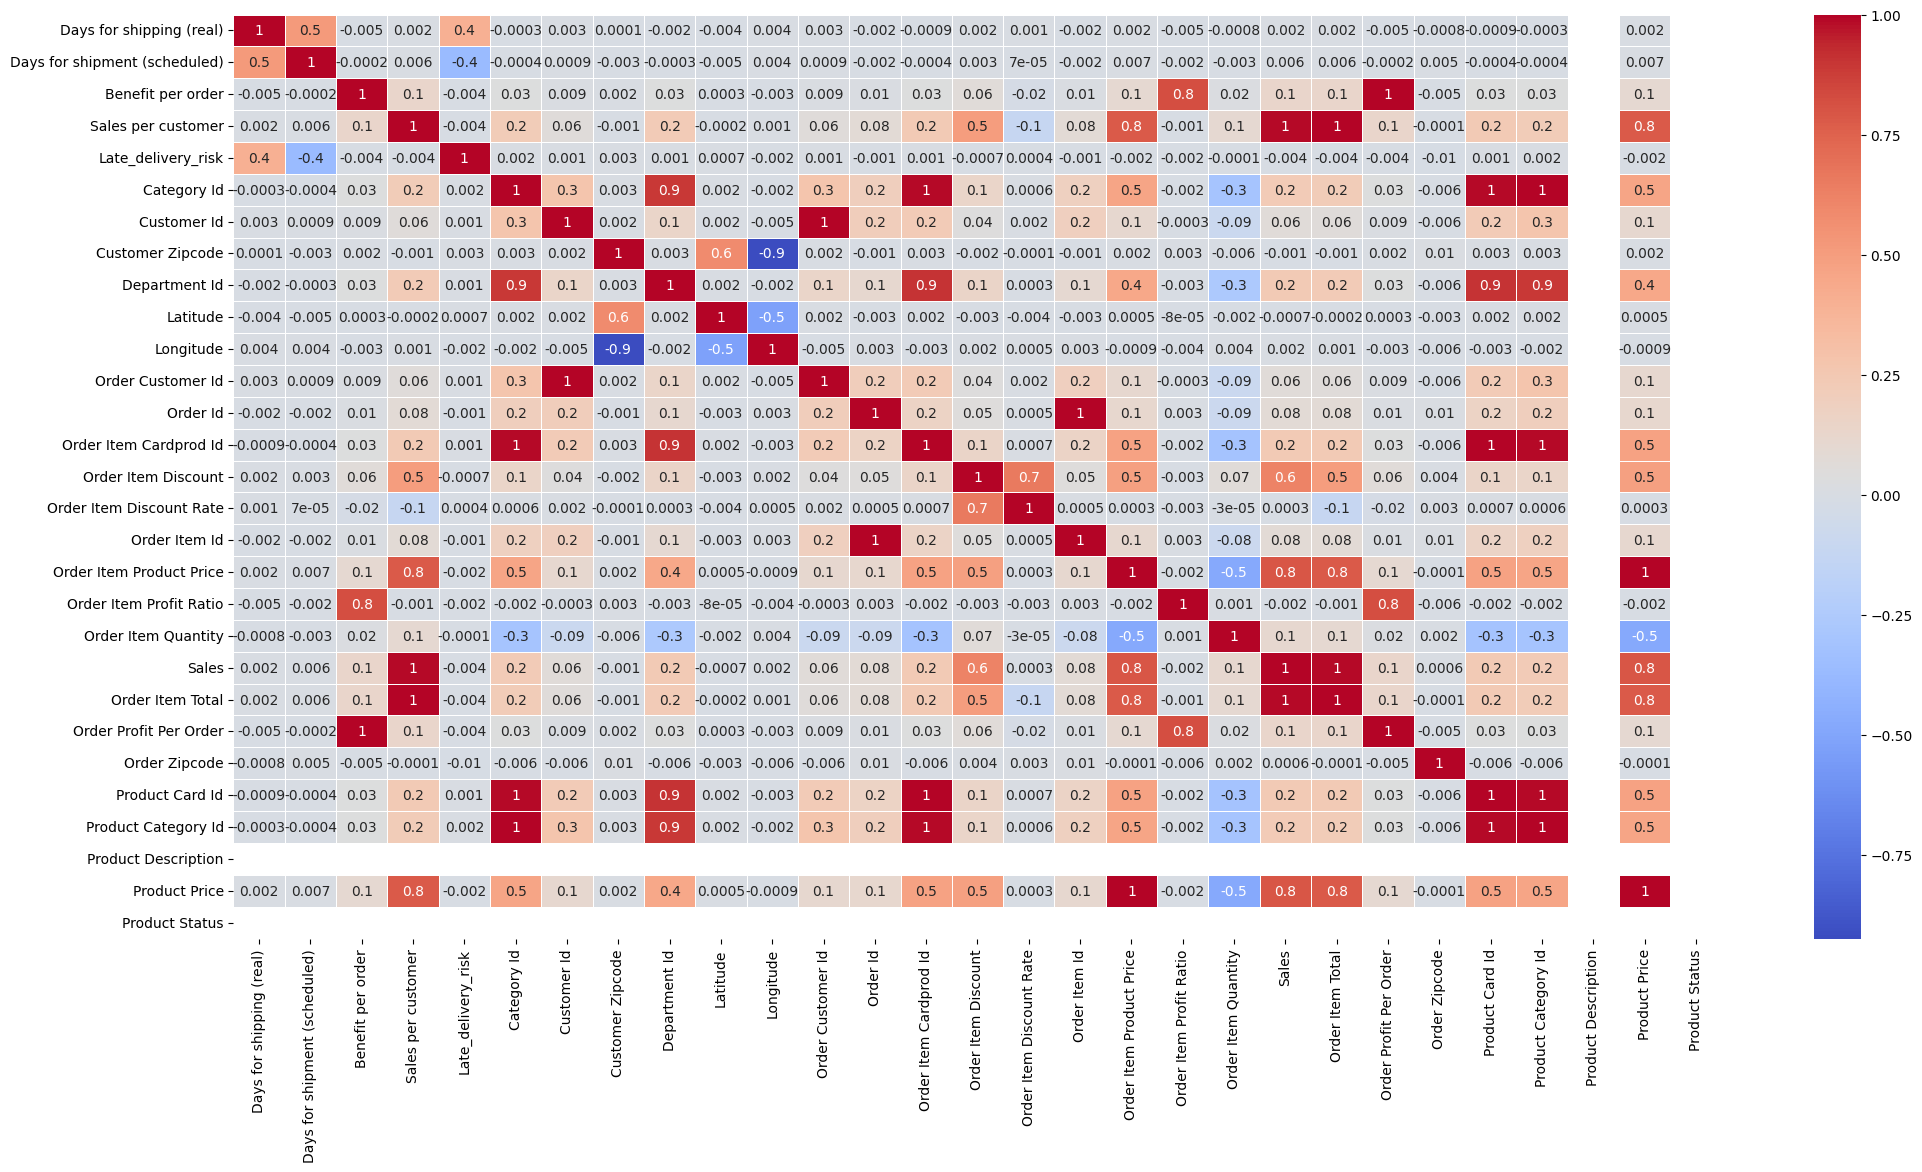

In [30]:
fig, ax = plt.subplots(figsize=(24, 12))

# Hitung korelasi hanya untuk kolom numerik
corr_matrix = df.corr(numeric_only=True)

# Tampilkan heatmap
sns.heatmap(corr_matrix, annot=True, linewidths=0.5, fmt='.1g', cmap='coolwarm', ax=ax)

plt.show()

<Axes: title={'center': 'Demand Each Category'}, xlabel='Category Name'>

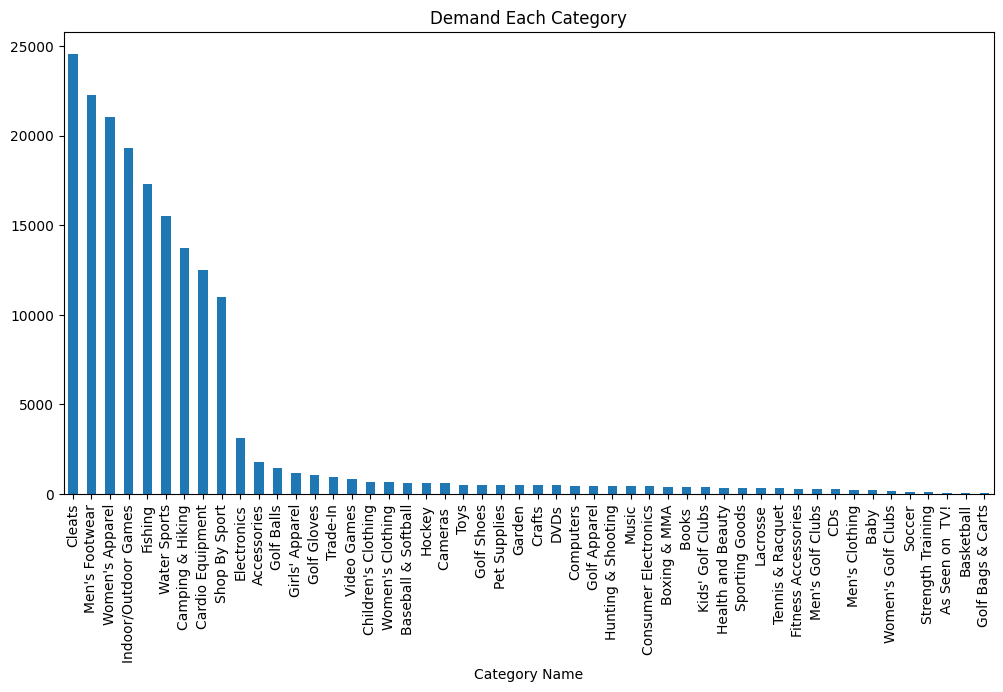

In [31]:
category = df.groupby('Category Name')
plt.figure(1)
category['Sales'].count().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Demand Each Category")

# TAHAP 1 — Data Preparation & Preprocessing
**Tujuan:** menyiapkan data transaksi (180.000+ baris) menjadi tabel permintaan harian per produk (SKU) yang bersih, lengkap dengan fitur untuk peramalan.

Langkah-langkahnya:
1. Pilih kolom yang dipakai, isi data kosong (imputasi)
2. Jumlahkan transaksi menjadi **permintaan harian per SKU**
3. Lengkapi hari tanpa transaksi dengan permintaan 0
4. Buat fitur: **lag 7 & 30 hari**, **rata-rata (mean)** dan **standar deviasi (std)** bergerak, serta fitur kalender
5. Bagi data **80% train / 20% test berdasarkan urutan waktu**, lalu lakukan **Standard Scaling**

In [32]:
# 1.1 Pilih kolom yang dipakai
COL_DATE = 'order date (DateOrders)'
COL_SKU  = 'Product Card Id'
COL_LT   = 'Days for shipping (real)'      # lead time aktual (hari)

kolom_dipakai = ['Order Id', COL_SKU, 'Product Name', COL_DATE, 'Sales',
                 'Order Item Quantity', COL_LT, 'Benefit per order', 'Shipping Mode']
df_prep = df[kolom_dipakai].copy()

print('Jumlah transaksi :', len(df_prep))
print('\nData kosong (missing values) per kolom:')
print(df_prep.isnull().sum())

Jumlah transaksi : 180519

Data kosong (missing values) per kolom:
Order Id                    0
Product Card Id             0
Product Name                0
order date (DateOrders)     0
Sales                       0
Order Item Quantity         0
Days for shipping (real)    0
Benefit per order           0
Shipping Mode               0
dtype: int64


In [33]:
# 1.2 Imputasi (mengisi data kosong)
# - Tanggal diubah ke format tanggal
df_prep[COL_DATE] = pd.to_datetime(df_prep[COL_DATE])
df_prep['Date'] = df_prep[COL_DATE].dt.normalize()        # tanggal tanpa jam

# - Kolom angka yang kosong diisi nilai tengah (median) milik produknya sendiri
kolom_angka = ['Sales', 'Order Item Quantity', COL_LT, 'Benefit per order']
for kolom in kolom_angka:
    median_per_sku = df_prep.groupby(COL_SKU)[kolom].transform('median')
    df_prep[kolom] = df_prep[kolom].fillna(median_per_sku)
    df_prep[kolom] = df_prep[kolom].fillna(df_prep[kolom].median())   # jaga-jaga jika masih kosong

# - Kolom kategori yang kosong diisi nilai yang paling sering muncul (modus)
df_prep['Shipping Mode'] = df_prep['Shipping Mode'].fillna(df_prep['Shipping Mode'].mode()[0])

print('Sisa data kosong :', df_prep.isnull().sum().sum())
print('Jumlah SKU       :', df_prep[COL_SKU].nunique())
print('Periode data     :', df_prep['Date'].min().date(), 's.d.', df_prep['Date'].max().date())

Sisa data kosong : 0
Jumlah SKU       : 118
Periode data     : 2015-01-01 s.d. 2018-01-31


In [34]:
# 1.3 Agregasi: jumlahkan transaksi menjadi PERMINTAAN HARIAN per SKU
daily = df_prep.groupby([COL_SKU, 'Date']).agg(
    Demand=('Order Item Quantity', 'sum'),          # total unit terjual per hari (target peramalan)
    Sales_Revenue=('Sales', 'sum'),                 # total nilai penjualan per hari
    Benefit=('Benefit per order', 'sum')
).reset_index()

display(daily.head())

,Product Card Id,Date,Demand,Sales_Revenue,Benefit
0,19,2017-04-24,1,124.989998,54.000000
1,19,2017-04-26,1,124.989998,52.320000
2,19,2017-05-03,1,124.989998,51.150002
3,19,2017-05-04,1,124.989998,56.700001
4,19,2017-05-06,1,124.989998,-86.089996


In [35]:
# 1.4 Lengkapi hari tanpa transaksi (permintaan = 0)
# Tanpa langkah ini, "lag 7 hari" akan salah karena hari kosong tidak ada barisnya.
daftar_panel = []
for sku_id, grup in daily.groupby(COL_SKU):
    # hanya dari tanggal pertama sampai terakhir produk itu terjual
    semua_hari = pd.date_range(grup['Date'].min(), grup['Date'].max(), freq='D')
    grup = grup.set_index('Date').reindex(semua_hari)
    grup.index.name = 'Date'
    grup[COL_SKU] = sku_id
    grup[['Demand', 'Sales_Revenue', 'Benefit']] = grup[['Demand', 'Sales_Revenue', 'Benefit']].fillna(0)
    daftar_panel.append(grup.reset_index())

panel = pd.concat(daftar_panel, ignore_index=True)
print('Ukuran tabel harian (SKU x hari):', panel.shape)
display(panel.head())

Ukuran tabel harian (SKU x hari): (52593, 5)


,Date,Product Card Id,Demand,Sales_Revenue,Benefit
0,2017-04-24,19,1.0,124.989998,54.00
1,2017-04-25,19,0.0,0.000000,0.00
2,2017-04-26,19,1.0,124.989998,52.32
3,2017-04-27,19,0.0,0.000000,0.00
4,2017-04-28,19,0.0,0.000000,0.00


In [36]:
# 1.5 Rekayasa fitur (dikerjakan per SKU)
# PENTING: semua fitur hanya memakai data SEBELUM hari yang diprediksi (tidak mengintip masa depan)
daftar_fitur = []
for sku_id, grup in panel.groupby(COL_SKU):
    grup = grup.sort_values('Date').copy()
    demand = grup['Demand']

    # Lag: permintaan 7 hari dan 30 hari yang lalu
    grup['lag_7']  = demand.shift(7)
    grup['lag_30'] = demand.shift(30)

    # Statistik deskriptif: mean & std permintaan 7 dan 30 hari terakhir (sampai kemarin)
    demand_kemarin = demand.shift(1)
    grup['roll_mean_7']  = demand_kemarin.rolling(7).mean()
    grup['roll_std_7']   = demand_kemarin.rolling(7).std()
    grup['roll_mean_30'] = demand_kemarin.rolling(30).mean()
    grup['roll_std_30']  = demand_kemarin.rolling(30).std()

    daftar_fitur.append(grup)

panel = pd.concat(daftar_fitur, ignore_index=True)

# Fitur kalender
panel['DayOfWeek']  = panel['Date'].dt.dayofweek
panel['DayOfMonth'] = panel['Date'].dt.day
panel['Month']      = panel['Date'].dt.month
panel['Quarter']    = panel['Date'].dt.quarter
panel['Is_Weekend'] = panel['DayOfWeek'].isin([5, 6]).astype(int)

FEATURES = ['lag_7', 'lag_30', 'roll_mean_7', 'roll_std_7', 'roll_mean_30', 'roll_std_30',
            'DayOfWeek', 'DayOfMonth', 'Month', 'Quarter', 'Is_Weekend']

# 30 hari pertama tiap SKU belum punya lag_30, jadi dibuang
model_df = panel.dropna(subset=FEATURES).reset_index(drop=True)
print('Ukuran feature matrix:', model_df.shape)
display(model_df[[COL_SKU, 'Date', 'Demand'] + FEATURES].head())

Ukuran feature matrix: (49263, 16)


,Product Card Id,Date,Demand,lag_7,lag_30,roll_mean_7,roll_std_7,roll_mean_30,roll_std_30,DayOfWeek,DayOfMonth,Month,Quarter,Is_Weekend
0,19,2017-05-24,1.0,0.0,1.0,0.714286,0.755929,0.400000,0.563242,2,24,5,2,0
1,19,2017-05-25,1.0,0.0,0.0,0.857143,0.690066,0.400000,0.563242,3,25,5,2,0
2,19,2017-05-26,0.0,1.0,1.0,1.000000,0.577350,0.433333,0.568321,4,26,5,2,0
3,19,2017-05-27,0.0,1.0,0.0,0.857143,0.690066,0.400000,0.563242,5,27,5,2,1
4,19,2017-05-28,1.0,0.0,0.0,0.714286,0.755929,0.400000,0.563242,6,28,5,2,1


In [37]:
# 1.6 Bagi data berdasarkan WAKTU (80% awal = train, 20% akhir = test) + Standard Scaling
tanggal_unik = np.sort(model_df['Date'].unique())
CUTOFF_DATE  = pd.Timestamp(tanggal_unik[int(len(tanggal_unik) * 0.80)])

train_mask = model_df['Date'] < CUTOFF_DATE     # True = baris train
test_mask  = ~train_mask                        # True = baris test

# Scaler hanya "belajar" dari data train, lalu dipakai untuk semua data
scaler = StandardScaler()
scaler.fit(model_df.loc[train_mask, FEATURES])
X_scaled = pd.DataFrame(scaler.transform(model_df[FEATURES]), columns=FEATURES, index=model_df.index)

print('Tanggal batas train/test :', CUTOFF_DATE.date())
print('Jumlah data train        :', train_mask.sum())
print('Jumlah data test         :', test_mask.sum())

Tanggal batas train/test : 2017-06-03
Jumlah data train        : 44392
Jumlah data test         : 4871


# TAHAP 2 — Segmentasi Inventori Multi-Kriteria (K-Means Clustering)
**Tujuan:** mengelompokkan SKU yang karakteristiknya mirip, supaya tiap kelompok bisa diberi model peramalan terbaiknya sendiri.

Lima kriteria per SKU:
| Kriteria | Arti |
|---|---|
| `Sales_Revenue` | total nilai penjualan (usage value) |
| `CV2` | seberapa besar permintaan berubah-ubah (variabilitas) |
| `ADI` | rata-rata jarak hari antar permintaan (makin besar = makin jarang laku) |
| `Lead_Time` | rata-rata lama pengiriman (hari) |
| `Criticality` | tingkat urgensi pengiriman (dari Shipping Mode, di-encode berurutan) |

> **Catatan:** dataset tidak punya kolom *criticality*, jadi dipakai Shipping Mode: Standard Class=1, Second Class=2, First Class=3, Same Day=4 (Ordinal Encoding), lalu dirata-ratakan per SKU.
> Kriteria dihitung dari **data train saja** agar data test tidak ikut "bocor" ke pengelompokan.

In [38]:
# 2.1 Hitung Sales_Revenue, ADI, dan CV2 per SKU (periode train)
train_panel = panel[panel['Date'] < CUTOFF_DATE]

sku_info = train_panel.groupby(COL_SKU).agg(
    Sales_Revenue=('Sales_Revenue', 'sum'),
    Jumlah_Hari=('Demand', 'size')                 # total hari pengamatan
)

# Statistik hanya pada hari yang ada permintaannya
hari_ada_demand = train_panel[train_panel['Demand'] > 0].groupby(COL_SKU)['Demand'].agg(
    Hari_Demand='count', Mean_Demand='mean', Std_Demand='std'
)
sku_info = sku_info.join(hari_ada_demand)

sku_info['ADI'] = sku_info['Jumlah_Hari'] / sku_info['Hari_Demand']                 # jeda rata-rata antar permintaan
sku_info['CV2'] = (sku_info['Std_Demand'] / sku_info['Mean_Demand']) ** 2           # variabilitas permintaan
sku_info['CV2'] = sku_info['CV2'].fillna(0)

display(sku_info[['Sales_Revenue', 'ADI', 'CV2']].head())

,Sales_Revenue,ADI,CV2
Product Card Id,,,
19,2124.829964,2.500000,0.055363
24,6639.170021,2.050000,0.478413
35,3359.790115,2.500000,0.133031
37,27327.190540,3.633621,0.310893
44,56330.611645,3.199234,0.381172


In [39]:
# 2.2 Hitung Lead_Time dan Criticality per SKU (periode train)
train_orders = df_prep[df_prep['Date'] < CUTOFF_DATE].copy()

# Ordinal Encoding: ubah Shipping Mode menjadi angka berurutan
urutan_shipping = {'Standard Class': 1, 'Second Class': 2, 'First Class': 3, 'Same Day': 4}
train_orders['Criticality'] = train_orders['Shipping Mode'].map(urutan_shipping)

sku_info['Lead_Time']   = train_orders.groupby(COL_SKU)[COL_LT].mean()
sku_info['Criticality'] = train_orders.groupby(COL_SKU)['Criticality'].mean()

CLUSTER_FEATURES = ['Sales_Revenue', 'CV2', 'ADI', 'Lead_Time', 'Criticality']
sku_info = sku_info.dropna(subset=CLUSTER_FEATURES)

print('Jumlah SKU yang dikelompokkan:', len(sku_info))
display(sku_info[CLUSTER_FEATURES].describe().T)

Jumlah SKU yang dikelompokkan: 87


,count,mean,std,min,25%,50%,75%,max
Sales_Revenue,87.0,344119.872869,1.049076e+06,1759.199950,4826.000000,20025.000000,29808.369764,6.064097e+06
CV2,87.0,0.272763,1.259301e-01,0.048200,0.174366,0.306612,0.344148,5.923269e-01
ADI,87.0,2.866307,8.362643e-01,1.000000,2.455882,3.218391,3.428571,4.750000e+00
Lead_Time,87.0,3.530299,2.074376e-01,3.074074,3.444492,3.500000,3.604409,4.300000e+00
Criticality,87.0,1.634082,1.210925e-01,1.250000,1.594919,1.654442,1.701768,1.954545e+00


k = 2 | Silhouette = 0.4336
k = 3 | Silhouette = 0.4563
k = 4 | Silhouette = 0.4576
k = 5 | Silhouette = 0.4340
k = 6 | Silhouette = 0.4332
k = 7 | Silhouette = 0.3431
k = 8 | Silhouette = 0.3441

Jumlah klaster terpilih (k): 4


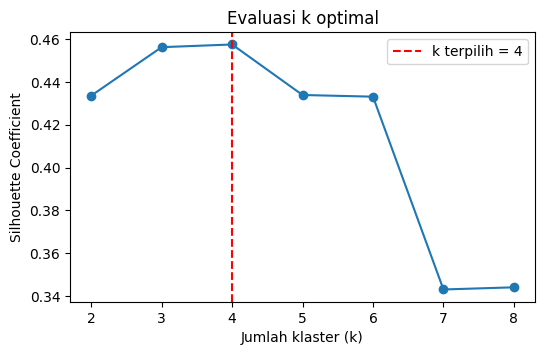

In [40]:
# 2.3 Min-Max Normalization: samakan skala semua kriteria menjadi 0 s.d. 1
X_cluster = MinMaxScaler().fit_transform(sku_info[CLUSTER_FEATURES])

# 2.4 Cari jumlah klaster (k) terbaik dengan Silhouette Coefficient (makin tinggi makin baik)
sil_scores = {}
for k in range(2, 9):
    label_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_cluster)
    sil_scores[k] = silhouette_score(X_cluster, label_k)
    print(f'k = {k} | Silhouette = {sil_scores[k]:.4f}')

K_OVERRIDE = None          # isi angka (misal 4) jika ingin menentukan jumlah klaster sendiri
best_k = K_OVERRIDE if K_OVERRIDE else max(sil_scores, key=sil_scores.get)
print('\nJumlah klaster terpilih (k):', best_k)

plt.figure(figsize=(6, 3.5))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'k terpilih = {best_k}')
plt.xlabel('Jumlah klaster (k)')
plt.ylabel('Silhouette Coefficient')
plt.title('Evaluasi k optimal')
plt.legend()
plt.show()

In [41]:
# 2.5 Jalankan K-Means dengan k terpilih
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
sku_info['Cluster'] = kmeans.fit_predict(X_cluster)

# Profil klaster = rata-rata tiap kriteria di dalam klaster
profil_klaster = sku_info.groupby('Cluster')[CLUSTER_FEATURES].mean()
profil_klaster['Jumlah_SKU'] = sku_info.groupby('Cluster').size()
display(profil_klaster.round(3))

# Beri nama klaster setelah membaca profil di atas. Contoh:
# CLUSTER_LABELS = {0: 'Strategic', 1: 'High-Value Operational', 2: 'General Slow-Moving', 3: 'Consumable'}
CLUSTER_LABELS = {c: f'Klaster {c}' for c in sorted(sku_info['Cluster'].unique())}
sku_info['Cluster_Label'] = sku_info['Cluster'].map(CLUSTER_LABELS)

,Sales_Revenue,CV2,ADI,Lead_Time,Criticality,Jumlah_SKU
Cluster,,,,,,
0,4392.050,0.240,2.766,3.875,1.404,11
1,24435.599,0.345,3.326,3.497,1.670,54
2,3169736.203,0.072,1.000,3.497,1.664,9
3,3305.246,0.137,2.336,3.398,1.659,13


Demand_Quadrant,Intermittent,Lumpy,Smooth
Cluster_Label,,,
Klaster 0,11,0,0
Klaster 1,52,2,0
Klaster 2,0,0,9
Klaster 3,13,0,0


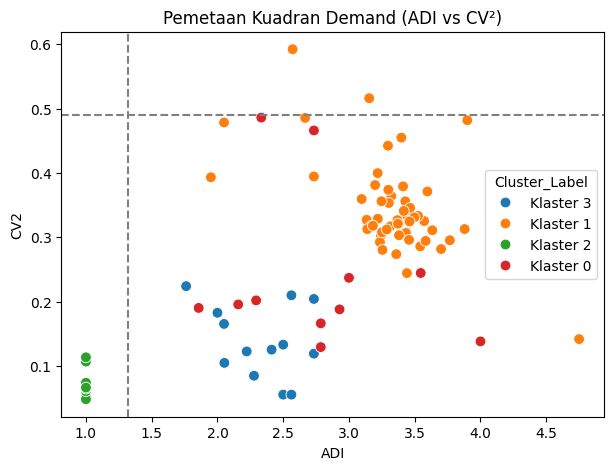

In [42]:
# 2.6 Pemetaan Kuadran Demand (ADI vs CV2) — batas standar: ADI = 1.32 dan CV2 = 0.49
def demand_quadrant(row):
    if row['ADI'] < 1.32 and row['CV2'] < 0.49:
        return 'Smooth'          # stabil & sering
    elif row['ADI'] < 1.32:
        return 'Erratic'         # sering tapi jumlahnya naik-turun
    elif row['CV2'] < 0.49:
        return 'Intermittent'    # jarang tapi jumlahnya stabil
    else:
        return 'Lumpy'           # jarang dan jumlahnya naik-turun

sku_info['Demand_Quadrant'] = sku_info.apply(demand_quadrant, axis=1)
display(pd.crosstab(sku_info['Cluster_Label'], sku_info['Demand_Quadrant']))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=sku_info, x='ADI', y='CV2', hue='Cluster_Label', palette='tab10', s=60)
plt.axvline(1.32, color='gray', linestyle='--')
plt.axhline(0.49, color='gray', linestyle='--')
plt.title('Pemetaan Kuadran Demand (ADI vs CV²)')
plt.show()

In [43]:
# 2.7 Tempelkan nomor klaster ke tabel fitur (setiap baris tahu SKU-nya ada di klaster mana)
model_df['Cluster'] = model_df[COL_SKU].map(sku_info['Cluster'])

# Buang SKU yang tidak punya klaster (jika ada), lalu sinkronkan tabel lain
model_df = model_df[model_df['Cluster'].notna()].copy()
model_df['Cluster'] = model_df['Cluster'].astype(int)
X_scaled   = X_scaled.loc[model_df.index]
train_mask = model_df['Date'] < CUTOFF_DATE
test_mask  = ~train_mask

print(model_df['Cluster'].value_counts().sort_index())

Cluster
0     1193
1    37353
2     8784
3     1420
Name: count, dtype: int64


# TAHAP 3 — Demand Forecasting Berbasis Machine Learning
**Tujuan:** melatih **7 algoritma** (Lasso, Ridge, SVR, Decision Tree, Random Forest, XGBoost, LightGBM) untuk meramalkan permintaan harian, **terpisah untuk setiap klaster**.

Cara kerjanya sama seperti notebook sebelumnya: fungsi `regression(model)` dibuat sekali, lalu dipanggil untuk tiap model. Bedanya, sekarang pengelompokannya berdasarkan **klaster K-Means** (bukan FSN), dan datanya dibagi **berdasarkan waktu**.

In [44]:
# 3.1 Persiapan: wadah hasil + fungsi MAPE
results_cluster = []                                           # menyimpan MAE, RMSE, MAPE tiap model-klaster
model_dict      = {}                                           # menyimpan model yang sudah dijalankan
test_pred       = pd.DataFrame(index=model_df.index[test_mask])  # menyimpan hasil prediksi di data test
SVR_MAX_TRAIN   = 20000                                        # SVR sangat lambat di data besar, jadi sampel train dibatasi

def hitung_mape(y_true, y_pred):
    # MAPE hanya dihitung pada hari yang permintaan aktualnya > 0 (jika 0, MAPE tidak bisa dihitung)
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    ada_demand = y_true > 0
    return np.mean(np.abs(y_true[ada_demand] - y_pred[ada_demand]) / y_true[ada_demand]) * 100

In [45]:
# 3.2 Fungsi regression: latih & uji satu model untuk SETIAP klaster
def regression(model):
    nama_model = type(model).__name__
    model_dict[nama_model] = model

    for c in sorted(model_df['Cluster'].unique()):
        # Ambil indeks baris train dan test milik klaster ini
        data_c   = model_df[model_df['Cluster'] == c]
        idx_train = data_c.index[data_c['Date'] < CUTOFF_DATE]
        idx_test  = data_c.index[data_c['Date'] >= CUTOFF_DATE]
        if len(idx_train) == 0 or len(idx_test) == 0:
            print(f'Klaster {c} tidak punya data train/test, dilewati\n')
            continue

        # Khusus SVR: ambil sampel acak agar tidak terlalu lama
        idx_fit = idx_train
        if nama_model == 'SVR' and len(idx_train) > SVR_MAX_TRAIN:
            idx_fit = np.random.RandomState(42).choice(idx_train, SVR_MAX_TRAIN, replace=False)

        # Latih model baru (clone) agar tiap klaster terpisah
        model_c = clone(model)
        model_c.fit(X_scaled.loc[idx_fit], model_df.loc[idx_fit, 'Demand'])

        # Prediksi data test (permintaan tidak mungkin negatif)
        y_pred = np.clip(model_c.predict(X_scaled.loc[idx_test]), 0, None)
        y_test = model_df.loc[idx_test, 'Demand']
        test_pred.loc[idx_test, nama_model] = y_pred

        # Hitung error
        mae  = metrics.mean_absolute_error(y_test, y_pred)
        mse  = metrics.mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        mape = hitung_mape(y_test, y_pred)

        print(f'=== KLASTER: {CLUSTER_LABELS[c]} | Model: {nama_model} ===')
        print(f'Jumlah Data Train : {len(idx_train)}')
        print(f'Jumlah Data Test  : {len(idx_test)}')
        print(f'MAE               : {mae:.4f}')
        print(f'RMSE              : {rmse:.4f}')
        print(f'MAPE (%)          : {mape:.2f}\n' + '-' * 50 + '\n')

        results_cluster.append({
            'Cluster': c, 'Cluster_Label': CLUSTER_LABELS[c], 'Model': nama_model,
            'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'MAPE_%': mape,
        })

In [46]:
model = Lasso(alpha=0.01, max_iter=10000)
regression(model)

=== KLASTER: Klaster 0 | Model: Lasso ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 1.2069
RMSE              : 1.8007
MAPE (%)          : 60.50
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: Lasso ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.5986
RMSE              : 2.2030
MAPE (%)          : 57.24
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: Lasso ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 7.9842
RMSE              : 11.2829
MAPE (%)          : 28.35
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: Lasso ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.7144
RMSE              : 0.9070
MAPE (%)          : 42.36
--------------------------------------------------



In [47]:
model = Ridge(alpha=1.0)
regression(model)

=== KLASTER: Klaster 0 | Model: Ridge ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 1.1529
RMSE              : 1.7969
MAPE (%)          : 66.49
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: Ridge ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.5964
RMSE              : 2.2007
MAPE (%)          : 56.97
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: Ridge ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 7.9862
RMSE              : 11.2829
MAPE (%)          : 28.35
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: Ridge ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.7169
RMSE              : 0.9138
MAPE (%)          : 42.04
--------------------------------------------------



In [48]:
model = SVR(kernel='rbf', C=10, epsilon=0.1)
regression(model)

=== KLASTER: Klaster 0 | Model: SVR ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 0.9884
RMSE              : 1.9193
MAPE (%)          : 89.35
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: SVR ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.3290
RMSE              : 2.4971
MAPE (%)          : 95.72
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: SVR ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 7.9948
RMSE              : 11.3186
MAPE (%)          : 28.19
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: SVR ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.6878
RMSE              : 1.0093
MAPE (%)          : 59.62
--------------------------------------------------



In [49]:
model = DecisionTreeRegressor(max_depth=10, random_state=42)
regression(model)

=== KLASTER: Klaster 0 | Model: DecisionTreeRegressor ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 1.4409
RMSE              : 2.5236
MAPE (%)          : 87.54
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: DecisionTreeRegressor ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.6048
RMSE              : 2.2352
MAPE (%)          : 61.43
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: DecisionTreeRegressor ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 9.5607
RMSE              : 14.1154
MAPE (%)          : 31.89
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: DecisionTreeRegressor ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.8422
RMSE              : 1.2577
MAPE (%)          : 49.30
--------------------------------------------------



In [50]:
model = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
regression(model)

=== KLASTER: Klaster 0 | Model: RandomForestRegressor ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 1.2165
RMSE              : 1.8002
MAPE (%)          : 50.82
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: RandomForestRegressor ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.6277
RMSE              : 2.2132
MAPE (%)          : 59.02
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: RandomForestRegressor ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 8.2267
RMSE              : 11.6205
MAPE (%)          : 28.93
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: RandomForestRegressor ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.7479
RMSE              : 0.9705
MAPE (%)          : 45.82
--------------------------------------------------



In [51]:
model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)
regression(model)

=== KLASTER: Klaster 0 | Model: XGBRegressor ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 1.2381
RMSE              : 2.0214
MAPE (%)          : 70.88
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: XGBRegressor ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.6455
RMSE              : 2.2320
MAPE (%)          : 63.20
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: XGBRegressor ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 8.5434
RMSE              : 12.0988
MAPE (%)          : 29.74
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: XGBRegressor ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.8299
RMSE              : 1.1131
MAPE (%)          : 53.78
--------------------------------------------------



In [52]:
model = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, force_row_wise=True, random_state=42, verbose=-1)
regression(model)

=== KLASTER: Klaster 0 | Model: LGBMRegressor ===
Jumlah Data Train : 102
Jumlah Data Test  : 1091
MAE               : 1.1556
RMSE              : 1.7880
MAPE (%)          : 63.23
--------------------------------------------------

=== KLASTER: Klaster 1 | Model: LGBMRegressor ===
Jumlah Data Train : 36471
Jumlah Data Test  : 882
MAE               : 1.6031
RMSE              : 2.2068
MAPE (%)          : 58.25
--------------------------------------------------

=== KLASTER: Klaster 2 | Model: LGBMRegressor ===
Jumlah Data Train : 7686
Jumlah Data Test  : 1098
MAE               : 8.2855
RMSE              : 11.8285
MAPE (%)          : 28.89
--------------------------------------------------

=== KLASTER: Klaster 3 | Model: LGBMRegressor ===
Jumlah Data Train : 133
Jumlah Data Test  : 1287
MAE               : 0.7234
RMSE              : 0.9678
MAPE (%)          : 51.65
--------------------------------------------------



# TAHAP 4 — Evaluasi Performa Model & Validasi Temporal
**Tujuan:** membandingkan akurasi ketujuh model dengan **MAE, RMSE, MAPE** (makin kecil makin baik), dan memastikan tidak ada kebocoran data waktu (*temporal leakage*).

In [53]:
# 4.1 Validasi temporal: pastikan data test benar-benar SETELAH data train
assert model_df.loc[train_mask, 'Date'].max() < model_df.loc[test_mask, 'Date'].min(), 'Data test bocor ke periode train!'

# lag_7 harus sama persis dengan permintaan 7 hari sebelumnya
cek_lag7 = panel.groupby(COL_SKU)['Demand'].shift(7)
assert np.allclose(panel['lag_7'], cek_lag7, equal_nan=True), 'lag_7 tidak sesuai'

print('Validasi temporal LOLOS')
print('Train :', model_df.loc[train_mask, 'Date'].min().date(), 's.d.', model_df.loc[train_mask, 'Date'].max().date())
print('Test  :', model_df.loc[test_mask, 'Date'].min().date(), 's.d.', model_df.loc[test_mask, 'Date'].max().date())

Validasi temporal LOLOS
Train : 2015-01-31 s.d. 2017-06-02
Test  : 2017-06-03 s.d. 2017-10-02


In [54]:
# 4.2 Tabel perbandingan hasil regresi untuk setiap klaster
Regression_comparision = pd.DataFrame(results_cluster)

for c in sorted(Regression_comparision['Cluster'].unique()):
    tabel = Regression_comparision[Regression_comparision['Cluster'] == c]
    tabel = tabel.drop(columns=['Cluster', 'Cluster_Label']).reset_index(drop=True)
    print(f'=== TABEL HASIL REGRESI: {CLUSTER_LABELS[c].upper()} ===')
    display(tabel.round(3))

=== TABEL HASIL REGRESI: KLASTER 0 ===


,Model,MAE,MSE,RMSE,MAPE_%
0,Lasso,1.207,3.242,1.801,60.503
1,Ridge,1.153,3.229,1.797,66.491
2,SVR,0.988,3.684,1.919,89.350
3,DecisionTreeRegressor,1.441,6.368,2.524,87.535
4,RandomForestRegressor,1.217,3.241,1.800,50.822
5,XGBRegressor,1.238,4.086,2.021,70.879
6,LGBMRegressor,1.156,3.197,1.788,63.233


=== TABEL HASIL REGRESI: KLASTER 1 ===


,Model,MAE,MSE,RMSE,MAPE_%
0,Lasso,1.599,4.853,2.203,57.238
1,Ridge,1.596,4.843,2.201,56.967
2,SVR,1.329,6.236,2.497,95.723
3,DecisionTreeRegressor,1.605,4.996,2.235,61.426
4,RandomForestRegressor,1.628,4.898,2.213,59.015
5,XGBRegressor,1.645,4.982,2.232,63.204
6,LGBMRegressor,1.603,4.870,2.207,58.248


=== TABEL HASIL REGRESI: KLASTER 2 ===


,Model,MAE,MSE,RMSE,MAPE_%
0,Lasso,7.984,127.305,11.283,28.348
1,Ridge,7.986,127.303,11.283,28.346
2,SVR,7.995,128.110,11.319,28.186
3,DecisionTreeRegressor,9.561,199.243,14.115,31.892
4,RandomForestRegressor,8.227,135.036,11.621,28.932
5,XGBRegressor,8.543,146.381,12.099,29.741
6,LGBMRegressor,8.286,139.913,11.828,28.887


=== TABEL HASIL REGRESI: KLASTER 3 ===


,Model,MAE,MSE,RMSE,MAPE_%
0,Lasso,0.714,0.823,0.907,42.360
1,Ridge,0.717,0.835,0.914,42.043
2,SVR,0.688,1.019,1.009,59.618
3,DecisionTreeRegressor,0.842,1.582,1.258,49.302
4,RandomForestRegressor,0.748,0.942,0.971,45.823
5,XGBRegressor,0.830,1.239,1.113,53.778
6,LGBMRegressor,0.723,0.937,0.968,51.653


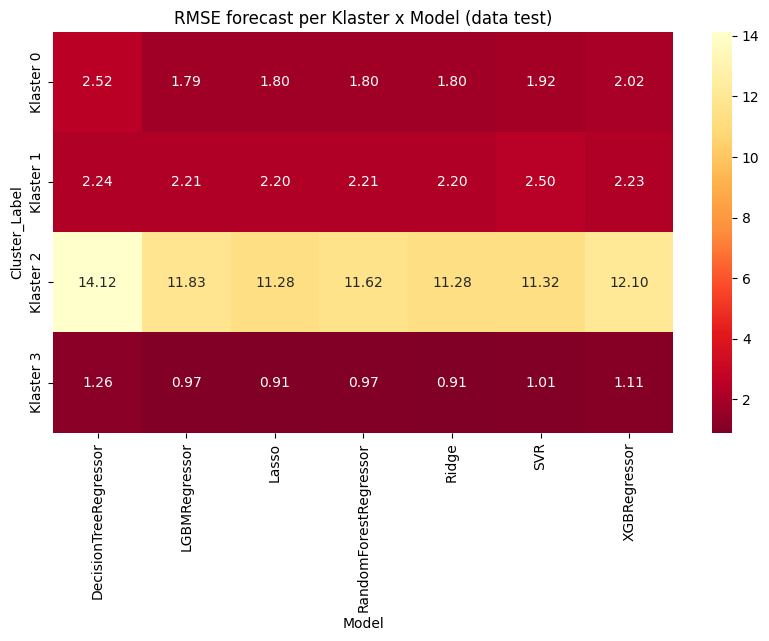

In [55]:
# 4.3 Heatmap RMSE (baris = klaster, kolom = model). Warna lebih terang = error lebih kecil
rmse_matrix = Regression_comparision.pivot(index='Cluster_Label', columns='Model', values='RMSE')

plt.figure(figsize=(10, 0.8 * len(rmse_matrix) + 2))
sns.heatmap(rmse_matrix, annot=True, fmt='.2f', cmap='YlOrRd_r')
plt.title('RMSE forecast per Klaster x Model (data test)')
plt.show()

# TAHAP 5 — Pemilihan Model Terbaik Spesifik Klaster
**Tujuan:** memilih satu model terbaik untuk **setiap klaster**. Pemilihan tidak hanya dari error di data test, tetapi juga dari **kestabilan** model lewat *rolling-origin* (model diuji berulang pada beberapa periode waktu berbeda).

Skor akhir = rata-rata peringkat dari 5 ukuran: MAE, RMSE, MAPE, rata-rata RMSE rolling-origin, dan variasi (std) RMSE rolling-origin. **Peringkat 1 = terbaik.**

In [56]:
# 5.1 Rolling-origin: latih pada data awal, uji pada blok waktu berikutnya, ulangi dengan data latih yang makin panjang
JUMLAH_FOLD = 3

def rolling_origin(model, data_train_klaster):
    tanggal = np.sort(data_train_klaster['Date'].unique())
    mulai   = int(len(tanggal) * 0.5)                  # 50% pertama = data latih awal
    ukuran_blok = (len(tanggal) - mulai) // JUMLAH_FOLD
    daftar_rmse = []

    for fold in range(JUMLAH_FOLD):
        batas_latih = mulai + fold * ukuran_blok
        batas_uji   = len(tanggal) if fold == JUMLAH_FOLD - 1 else batas_latih + ukuran_blok

        latih = data_train_klaster[data_train_klaster['Date'].isin(tanggal[:batas_latih])]
        uji   = data_train_klaster[data_train_klaster['Date'].isin(tanggal[batas_latih:batas_uji])]

        sc = StandardScaler()
        X_latih = sc.fit_transform(latih[FEATURES])
        X_uji   = sc.transform(uji[FEATURES])
        y_latih = latih['Demand'].values

        # Khusus SVR: batasi sampel
        if type(model).__name__ == 'SVR' and len(X_latih) > SVR_MAX_TRAIN:
            pilih = np.random.RandomState(42).choice(len(X_latih), SVR_MAX_TRAIN, replace=False)
            X_latih, y_latih = X_latih[pilih], y_latih[pilih]

        model_f = clone(model)
        model_f.fit(X_latih, y_latih)
        y_pred = np.clip(model_f.predict(X_uji), 0, None)
        daftar_rmse.append(np.sqrt(metrics.mean_squared_error(uji['Demand'], y_pred)))

    return daftar_rmse

hasil_rolling = []
for c in sorted(model_df['Cluster'].unique()):
    data_train_klaster = model_df[(model_df['Cluster'] == c) & train_mask]
    for nama_model, model in model_dict.items():
        rmse_fold = rolling_origin(model, data_train_klaster)
        hasil_rolling.append({'Cluster': c, 'Model': nama_model,
                              'Roll_RMSE_mean': np.mean(rmse_fold),
                              'Roll_RMSE_std':  np.std(rmse_fold)})
    print(f'Rolling-origin klaster {c} selesai')

df_rolling = pd.DataFrame(hasil_rolling)
display(df_rolling.round(3))

Rolling-origin klaster 0 selesai
Rolling-origin klaster 1 selesai
Rolling-origin klaster 2 selesai
Rolling-origin klaster 3 selesai


,Cluster,Model,Roll_RMSE_mean,Roll_RMSE_std
0,0,Lasso,2.099,0.009
1,0,Ridge,1.986,0.230
2,0,SVR,1.926,0.094
3,0,DecisionTreeRegressor,1.992,0.733
4,0,RandomForestRegressor,1.746,0.385
5,0,XGBRegressor,2.333,0.297
6,0,LGBMRegressor,1.858,0.190
7,1,Lasso,1.964,0.017
8,1,Ridge,1.965,0.016
9,1,SVR,2.172,0.017


In [57]:
# 5.2 Gabungkan semua hasil, lalu beri peringkat
df_res = Regression_comparision.merge(df_rolling, on=['Cluster', 'Model'])

kolom_peringkat = ['MAE', 'RMSE', 'MAPE_%', 'Roll_RMSE_mean', 'Roll_RMSE_std']
for kolom in kolom_peringkat:
    df_res['Rank_' + kolom] = df_res.groupby('Cluster')[kolom].rank()     # peringkat 1 = error terkecil

df_res['Avg_Error_Rank'] = df_res[['Rank_' + k for k in kolom_peringkat]].mean(axis=1)

# 5.3 Fungsi untuk menampilkan model terbaik tiap klaster
best_model = {}      # {nomor klaster: nama model terbaik}

def get_best_models(df):
    for c in sorted(df['Cluster'].unique()):
        sub = df[df['Cluster'] == c]
        print(f'=== MODEL TERBAIK KLASTER: {CLUSTER_LABELS[c].upper()} ===')

        for m in ['MAE', 'RMSE', 'MAPE_%']:
            baris = sub.loc[sub[m].idxmin()]
            print(f'• {m:<7} terkecil ({baris[m]:.4f}) : {baris["Model"]}')

        baris = sub.loc[sub['Roll_RMSE_std'].idxmin()]
        print(f'• Paling stabil (std RMSE {baris["Roll_RMSE_std"]:.4f}) : {baris["Model"]}')

        terbaik = sub.sort_values('Avg_Error_Rank').iloc[0]
        best_model[c] = terbaik['Model']
        print(f'-> MODEL TERBAIK KESELURUHAN : {terbaik["Model"]}\n' + '-' * 45)

get_best_models(df_res)

=== MODEL TERBAIK KLASTER: KLASTER 0 ===
• MAE     terkecil (0.9884) : SVR
• RMSE    terkecil (1.7880) : LGBMRegressor
• MAPE_%  terkecil (50.8218) : RandomForestRegressor
• Paling stabil (std RMSE 0.0089) : Lasso
-> MODEL TERBAIK KESELURUHAN : LGBMRegressor
---------------------------------------------
=== MODEL TERBAIK KLASTER: KLASTER 1 ===
• MAE     terkecil (1.3290) : SVR
• RMSE    terkecil (2.2007) : Ridge
• MAPE_%  terkecil (56.9674) : Ridge
• Paling stabil (std RMSE 0.0098) : XGBRegressor
-> MODEL TERBAIK KESELURUHAN : Ridge
---------------------------------------------
=== MODEL TERBAIK KLASTER: KLASTER 2 ===
• MAE     terkecil (7.9842) : Lasso
• RMSE    terkecil (11.2829) : Ridge
• MAPE_%  terkecil (28.1863) : SVR
• Paling stabil (std RMSE 0.1816) : RandomForestRegressor
-> MODEL TERBAIK KESELURUHAN : Ridge
---------------------------------------------
=== MODEL TERBAIK KLASTER: KLASTER 3 ===
• MAE     terkecil (0.6878) : SVR
• RMSE    terkecil (0.9070) : Lasso
• MAPE_%  terk

# TAHAP 6 — Dynamic Safety Stock & Dynamic Reorder Point
**Tujuan:** menghitung stok pengaman (*safety stock*) dan titik pemesanan ulang (*reorder point*) yang **dinamis**, yaitu memakai **kesalahan peramalan (RMSE forecast)** sebagai ukuran ketidakpastian permintaan, bukan standar deviasi permintaan biasa.

$$SS_{dynamic} = Z \times \sqrt{L \times RMSE_{forecast}^2 + d^2 \times \sigma_L^2}$$

$$ROP_{dynamic} = d \times L + SS_{dynamic}$$

| Simbol | Arti | Sumber di kode |
|---|---|---|
| `d` | rata-rata prediksi permintaan harian (Dpred) | prediksi model terbaik di data test |
| `RMSE_forecast` | rata-rata kesalahan peramalan | selisih aktual vs prediksi di data test |
| `L` | lead time rata-rata (hari) | rata-rata `days_for_shipping_real` |
| `σL` | simpangan baku lead time | std `days_for_shipping_real` |
| `Z` | faktor service level (1,65 untuk ±95%) | ditetapkan |

In [58]:
# 6.1 Ambil prediksi model terbaik (Dpred) untuk tiap klaster
test_eval = model_df.loc[test_mask, [COL_SKU, 'Cluster', 'Date', 'Demand']].copy()
test_eval['Dpred'] = np.nan

for c, nama_model in best_model.items():
    baris_klaster = test_eval['Cluster'] == c
    test_eval.loc[baris_klaster, 'Dpred'] = test_pred.loc[test_eval.index[baris_klaster], nama_model]

test_eval['Error']    = test_eval['Demand'] - test_eval['Dpred']
test_eval['Error_sq'] = test_eval['Error'] ** 2

# 6.2 Rangkum per SKU: d (rata-rata prediksi) dan RMSE forecast
df_inventory = test_eval.groupby(COL_SKU).agg(
    Cluster=('Cluster', 'first'),
    d=('Dpred', 'mean'),
    MSE_forecast=('Error_sq', 'mean')
)
df_inventory['RMSE_forecast'] = np.sqrt(df_inventory['MSE_forecast'])

# 6.3 Tambahkan lead time rata-rata (L) dan simpangannya (sigma_L) per SKU
lead_time = df_prep.groupby(COL_SKU)[COL_LT].agg(L='mean', sigma_L='std')
lead_time['sigma_L'] = lead_time['sigma_L'].fillna(0)
df_inventory = df_inventory.join(lead_time)

display(df_inventory.head())

,Cluster,d,MSE_forecast,RMSE_forecast,L,sigma_L
Product Card Id,,,,,,
19,3,0.650838,0.479540,0.692488,3.890625,1.710075
24,1,1.066627,6.136196,2.477135,3.554054,1.729216
35,3,0.656726,0.527446,0.726254,3.353846,1.555542
78,1,1.045910,3.683456,1.919233,3.603175,1.497737
191,2,36.188572,177.392534,13.318879,3.493960,1.620662


In [59]:
# 6.4 Fungsi perhitungan Dynamic Safety Stock & Dynamic ROP
def calculate_dynamic_inventory(demand, lead_time, rmse_forecast, sigma_l, z):
    """Menghitung Dynamic Safety Stock (SS) dan Reorder Point (ROP)."""

    # Gabungan ketidakpastian permintaan (RMSE forecast) dan ketidakpastian lead time
    variance = (lead_time * rmse_forecast ** 2) + (demand ** 2 * sigma_l ** 2)

    # Safety Stock dinamis
    safety_stock = z * np.sqrt(variance)

    # Reorder Point dinamis
    reorder_point = (demand * lead_time) + safety_stock

    return round(safety_stock, 2), round(reorder_point, 2)

In [60]:
# 6.5 Terapkan ke setiap SKU
SERVICE_LEVEL_Z = 1.65     # service level ±95%

ss_list  = []
rop_list = []
for sku_id, row in df_inventory.iterrows():
    ss, rop = calculate_dynamic_inventory(
        demand=row['d'],
        lead_time=row['L'],
        rmse_forecast=row['RMSE_forecast'],
        sigma_l=row['sigma_L'],
        z=SERVICE_LEVEL_Z
    )
    ss_list.append(ss)
    rop_list.append(rop)

df_inventory['Safety_Stock'] = ss_list
df_inventory['Reorder_Point'] = rop_list
df_inventory['Cluster_Label'] = df_inventory['Cluster'].map(CLUSTER_LABELS)
df_inventory['Model_Terbaik'] = df_inventory['Cluster'].map(best_model)
df_inventory['Product Name']  = df_prep.drop_duplicates(COL_SKU).set_index(COL_SKU)['Product Name']

df_master_inventory = df_inventory.copy()
print('=== PERHITUNGAN DYNAMIC SS & ROP SELESAI ===')
print(f'• Service Level Z : {SERVICE_LEVEL_Z} (~95%)')
display(df_master_inventory[['Product Name', 'Cluster_Label', 'Model_Terbaik', 'd', 'L', 'sigma_L',
                             'RMSE_forecast', 'Safety_Stock', 'Reorder_Point']].round(2).head(10))

=== PERHITUNGAN DYNAMIC SS & ROP SELESAI ===
• Service Level Z : 1.65 (~95%)


,Product Name,Cluster_Label,Model_Terbaik,d,L,sigma_L,RMSE_forecast,Safety_Stock,Reorder_Point
Product Card Id,,,,,,,,,
19,Nike Men's Fingertrap Max Training Shoe,Klaster 3,Lasso,0.65,3.89,1.71,0.69,2.91,5.44
24,Elevation Training Mask 2.0,Klaster 1,Ridge,1.07,3.55,1.73,2.48,8.28,12.08
35,adidas Brazuca 2014 Official Match Ball,Klaster 3,Lasso,0.66,3.35,1.56,0.73,2.77,4.97
78,Nike Kids' Grade School KD VI Basketball Shoe,Klaster 1,Ridge,1.05,3.60,1.50,1.92,6.54,10.31
191,Nike Men's Free 5.0+ Running Shoe,Klaster 2,Ridge,36.19,3.49,1.62,13.32,105.13,231.57
216,Yakima DoubleDown Ace Hitch Mount 4-Bike Rack,Klaster 0,LGBMRegressor,0.39,3.80,1.54,0.75,2.60,4.06
251,Brooks Women's Ghost 6 Running Shoe,Klaster 0,LGBMRegressor,1.40,3.45,1.57,2.67,8.97,13.81
258,Nike Women's Free 5.0 TR FIT PRT 4 Training S,Klaster 0,LGBMRegressor,1.69,3.56,1.69,2.37,8.74,14.75
295,Fitbit The One Wireless Activity & Sleep Trac,Klaster 1,Ridge,1.06,3.52,1.71,2.32,7.77,11.50


,Jumlah_SKU,Rata2_Demand_d,Rata2_RMSE,SS_Statis,SS_Dinamis,ROP_Dinamis
Cluster_Label,,,,,,
Klaster 0,11,0.90,1.56,5.10,5.45,8.68
Klaster 1,9,1.06,2.14,7.28,7.26,11.00
Klaster 2,9,36.12,10.08,101.39,101.83,228.12
Klaster 3,13,0.72,0.82,3.08,3.16,5.64


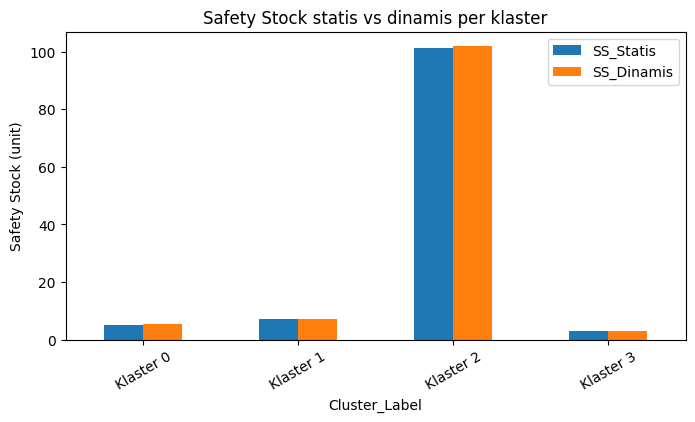

In [61]:
# 6.6 Pembanding: SS jika memakai standar deviasi permintaan biasa (statis) — untuk melihat dampak RMSE forecast
sigma_statis = train_panel.groupby(COL_SKU)['Demand'].std()

ss_statis = []
for sku_id, row in df_inventory.iterrows():
    ss, rop = calculate_dynamic_inventory(row['d'], row['L'], sigma_statis[sku_id], row['sigma_L'], SERVICE_LEVEL_Z)
    ss_statis.append(ss)
df_inventory['SS_Statis'] = ss_statis

# 6.7 Ringkasan per klaster
ringkasan_klaster = df_inventory.groupby('Cluster_Label').agg(
    Jumlah_SKU=('d', 'size'),
    Rata2_Demand_d=('d', 'mean'),
    Rata2_RMSE=('RMSE_forecast', 'mean'),
    SS_Statis=('SS_Statis', 'mean'),
    SS_Dinamis=('Safety_Stock', 'mean'),
    ROP_Dinamis=('Reorder_Point', 'mean')
)
display(ringkasan_klaster.round(2))

ringkasan_klaster[['SS_Statis', 'SS_Dinamis']].plot(kind='bar', figsize=(8, 4))
plt.ylabel('Safety Stock (unit)')
plt.title('Safety Stock statis vs dinamis per klaster')
plt.xticks(rotation=30)
plt.show()

In [62]:
# 6.8 Simpan hasil ke file CSV
df_inventory.to_csv('hasil_dynamic_ss_rop_per_sku.csv')
Regression_comparision.to_csv('hasil_evaluasi_model_per_klaster.csv', index=False)
sku_info.to_csv('hasil_segmentasi_kmeans_per_sku.csv')
print('File tersimpan: hasil_dynamic_ss_rop_per_sku.csv, hasil_evaluasi_model_per_klaster.csv, hasil_segmentasi_kmeans_per_sku.csv')

File tersimpan: hasil_dynamic_ss_rop_per_sku.csv, hasil_evaluasi_model_per_klaster.csv, hasil_segmentasi_kmeans_per_sku.csv
